<a href="https://colab.research.google.com/github/Darkcode-Git/Metodolog-a-CRISP-DM/blob/main/Parra_Juan_Analizando_EA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install yfinance pandas numpy matplotlib openpyxl


ANÁLISIS FINANCIERO AUTOMATIZADO CON ANÁLISIS DE BALANCE


Procesando Ecopetrol (EC)...
Gráfico generado: grafico_Ecopetrol.png

Procesando Bancolombia (CIB)...
Gráfico generado: grafico_Bancolombia.png

Procesando Grupo Aval (AVAL)...
Gráfico generado: grafico_Grupo Aval.png

Procesando Apple (AAPL)...
Gráfico generado: grafico_Apple.png

Procesando Microsoft (MSFT)...
Gráfico generado: grafico_Microsoft.png

Procesando Google (GOOGL)...
Gráfico generado: grafico_Google.png

Procesando Amazon (AMZN)...
Gráfico generado: grafico_Amazon.png

Procesando Nvidia (NVDA)...
Gráfico generado: grafico_Nvidia.png

Procesando Meta (META)...
Gráfico generado: grafico_Meta.png

Procesando Tesla (TSLA)...
Gráfico generado: grafico_Tesla.png

CSV generado: reporte_acciones_20261109.csv
Excel generado: reporte_acciones_20261109.xlsx

TOP ACCIONES Y CRECIMIENTO DE BALANCE
       Empresa  Precio Actual  Rendimiento %  Volatilidad %  \
0    Ecopetrol          15.61          65.84          40.27   
1  B

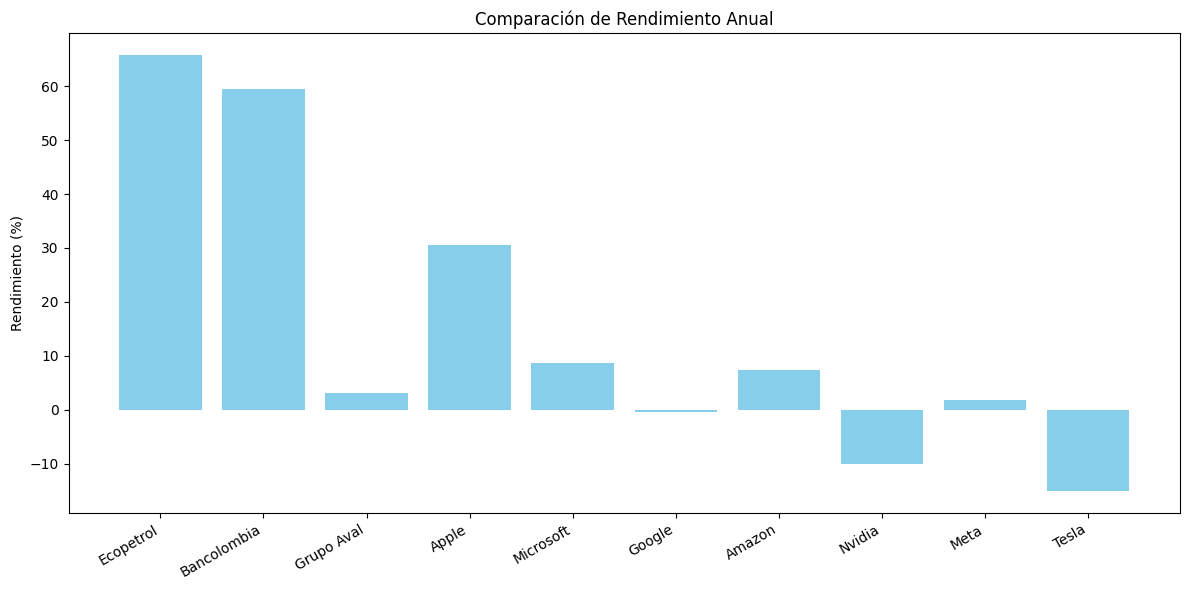


Proceso finalizado.


In [ ]:
"""
=========================================================
ANÁLISIS DE ACCIONES PARA APOYO A DECISIONES DE INVERSIÓN
=========================================================

Fuente:
Yahoo Finance

Autor:
Juan Felipe Parra Palacios
"""

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ---------------------------------------------------------
# CONFIGURACIÓN (10 Empresas muy importantes y listadas)
# ---------------------------------------------------------

ACCIONES = {
    "Ecopetrol": "EC",
    "Bancolombia": "CIB",
    "Grupo Aval": "AVAL",
    "Apple": "AAPL",
    "Microsoft": "MSFT",
    "Google": "GOOGL",
    "Amazon": "AMZN",
    "Nvidia": "NVDA",
    "Meta": "META",
    "Tesla": "TSLA"
}

PERIODO = "1y"

# ---------------------------------------------------------
# DESCARGA HISTÓRICA Y BALANCES
# ---------------------------------------------------------

def descargar_datos(ticker):
    try:
        accion = yf.Ticker(ticker)
        historial = accion.history(period=PERIODO)

        # Validar si el activo tiene datos históricos de precio
        if historial is None or historial.empty:
            print(f"Advertencia: {ticker} no tiene datos históricos o está deslistado.")
            return None, None, None

        info = accion.info

        # Obtener balances financieros trimestrales
        balances = accion.quarterly_balance_sheet

        return historial, info, balances
    except Exception as e:
        print(f"Error al descargar {ticker}: {e}")
        return None, None, None

# ---------------------------------------------------------
# INDICADORES
# ---------------------------------------------------------

def calcular_indicadores(df):
    df["SMA20"] = df["Close"].rolling(20).mean()
    df["SMA50"] = df["Close"].rolling(50).mean()
    df["Retorno Diario"] = df["Close"].pct_change()
    return df

# ---------------------------------------------------------
# COMPARATIVA TRIMESTRAL INTERANUAL
# ---------------------------------------------------------

def obtener_comparativa_balance(balances):
    if balances is None or balances.empty or len(balances.columns) < 5:
        return "N/A"
    try:
        # Comparar el último trimestre reportado (Columna 0) con el mismo trimestre del año anterior (Columna 4 aprox o la más cercana a 365 días)
        ultimo_trimestre = balances.columns[0]
        trimestre_anterior_ano = None

        # Buscar una columna que sea aproximadamente un año anterior
        for col in balances.columns[1:]:
            diff_dias = abs((ultimo_trimestre - col).days)
            if 340 <= diff_dias <= 390:
                trimestre_anterior_ano = col
                break

        if trimestre_anterior_ano is None:
            # Si no se encuentra la fecha exacta, tomar la cuarta columna disponible
            trimestre_anterior_ano = balances.columns[4] if len(balances.columns) > 4 else balances.columns[-1]

        # Usar 'Total Assets' (Activos Totales) como métrica de ejemplo de balance
        fila_activos = [idx for idx in balances.index if 'Total Assets' in str(idx)]
        if fila_activos:
            activos_actual = balances.loc[fila_activos[0]].iloc[0]
            activos_anterior = balances.loc[fila_activos[0]].loc[trimestre_anterior_ano]

            if pd.notna(activos_actual) and pd.notna(activos_anterior) and activos_anterior != 0:
                cambio_pct = ((activos_actual - activos_anterior) / activos_anterior) * 100
                return f"{round(cambio_pct, 2)}%"
        return "Sin Activos"
    except Exception:
        return "Error Cálculo"

# ---------------------------------------------------------
# MÉTRICAS FINANCIERAS
# ---------------------------------------------------------

def resumen_financiero(nombre, ticker):
    resultado = descargar_datos(ticker)
    if resultado is None or resultado[0] is None:
        return None

    hist, info, balances = resultado
    hist = calcular_indicadores(hist)

    rendimiento = ((hist["Close"].iloc[-1] / hist["Close"].iloc[0]) - 1) * 100
    volatilidad = hist["Retorno Diario"].std() * np.sqrt(252) * 100

    std_retorno = hist["Retorno Diario"].std()
    sharpe = (hist["Retorno Diario"].mean() / std_retorno) * np.sqrt(252) if std_retorno != 0 else 0

    crecimiento_activos_interanual = obtener_comparativa_balance(balances)

    resultado_dict = {
        "Empresa": nombre,
        "Ticker": ticker,
        "Precio Actual": round(hist["Close"].iloc[-1], 2),
        "Precio Máximo": round(hist["High"].max(), 2),
        "Precio Mínimo": round(hist["Low"].min(), 2),
        "Rendimiento %": round(rendimiento, 2),
        "Volatilidad %": round(volatilidad, 2),
        "Sharpe Ratio": round(sharpe, 2),
        "Volumen Promedio": int(hist["Volume"].mean()),
        "Crec. Activos Trimestral YoY": crecimiento_activos_interanual,
        "Market Cap": info.get("marketCap", "N/A"),
        "Sector": info.get("sector", "N/A"),
        "Dividend Yield": info.get("dividendYield", "N/A")
    }

    return resultado_dict, hist

# ---------------------------------------------------------
# GRÁFICOS
# ---------------------------------------------------------

def graficar_accion(nombre, df):
    plt.figure(figsize=(10, 5))
    plt.plot(df.index, df["Close"], label="Precio")
    plt.plot(df.index, df["SMA20"], label="SMA20")
    plt.plot(df.index, df["SMA50"], label="SMA50")
    plt.title(f"Análisis de {nombre}")
    plt.xlabel("Fecha")
    plt.ylabel("Precio")
    plt.legend()
    plt.grid(True)
    archivo = f"grafico_{nombre}.png"
    plt.savefig(archivo, dpi=300, bbox_inches="tight")
    plt.close()
    print(f"Gráfico generado: {archivo}")

# ---------------------------------------------------------
# PROCESAMIENTO
# ---------------------------------------------------------

def procesar_acciones():
    resumenes = []
    for nombre, ticker in ACCIONES.items():
        print(f"\nProcesando {nombre} ({ticker})...")
        resultado = resumen_financiero(nombre, ticker)

        if resultado:
            datos, historial = resultado
            resumenes.append(datos)
            graficar_accion(nombre, historial)
            historial.to_csv(f"{ticker}_historico.csv")

    return pd.DataFrame(resumenes)

# ---------------------------------------------------------
# EXPORTACIÓN
# ---------------------------------------------------------

def exportar(df):
    if df.empty:
        print("\nNo hay datos para exportar.")
        return
    fecha = datetime.now().strftime("%Y%m%d")
    csv = f"reporte_acciones_{fecha}.csv"
    excel = f"reporte_acciones_{fecha}.xlsx"

    df.to_csv(csv, index=False)
    df.to_excel(excel, index=False)
    print(f"\nCSV generado: {csv}")
    print(f"Excel generado: {excel}")

# ---------------------------------------------------------
# TOP RENDIMIENTO
# ---------------------------------------------------------

def top_acciones(df):
    if df.empty:
        return
    ranking = df.sort_values(by="Rendimiento %", ascending=False)
    print("\n" + "=" * 85)
    print("TOP ACCIONES Y CRECIMIENTO DE BALANCE")
    print("=" * 85)
    print(ranking[["Empresa", "Precio Actual", "Rendimiento %", "Volatilidad %", "Crec. Activos Trimestral YoY"]])

# ---------------------------------------------------------
# DASHBOARD BÁSICO
# ---------------------------------------------------------

def dashboard(df):
    if df.empty:
        return
    plt.figure(figsize=(12, 6))
    plt.bar(df["Empresa"], df["Rendimiento %"], color='skyblue')
    plt.title("Comparación de Rendimiento Anual")
    plt.ylabel("Rendimiento (%)")
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig("dashboard_rendimiento.png", dpi=300)
    plt.show()

# ---------------------------------------------------------
# MAIN
# ---------------------------------------------------------

def main():
    print("\nANÁLISIS FINANCIERO AUTOMATIZADO CON ANÁLISIS DE BALANCE\n")
    resumen = procesar_acciones()
    exportar(resumen)
    top_acciones(resumen)
    dashboard(resumen)
    print("\nProceso finalizado.")

if __name__ == "__main__":
    main()

In [ ]:
import requests
from bs4 import BeautifulSoup
import yfinance as yf

def obtener_perfil_avanzado(ticker):
    """
    Metodología híbrida:
    Intenta Web Scraping con BeautifulSoup usando Headers de navegador real.
    Si el portal bloquea la petición (detecta bot), utiliza la API oficial de yfinance
    como fallback para garantizar la extracción segura de los metadatos.
    """
    url = f"https://finance.yahoo.com/quote/{ticker}/profile/"
    headers = {
        "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
        "Accept-Language": "es-ES,es;q=0.9,en;q=0.8",
        "Referer": "https://www.google.com/"
    }

    try:
        response = requests.get(url, headers=headers, timeout=10)
        soup = BeautifulSoup(response.text, 'html.parser')

        # Intentar obtener la descripción si no fuimos bloqueados
        desc_element = soup.find('section', {'class': 'description'})
        if desc_element and "Oops" not in desc_element.get_text():
            descripcion = desc_element.get_text().strip()
            metodo = "Web Scraping (BeautifulSoup)"
        else:
            # Fallback seguro usando la API del Ticker que simula la interacción del navegador
            info = yf.Ticker(ticker).info
            descripcion = info.get("longBusinessSummary", "No disponible")
            metodo = "API Fallback (yfinance)"

        return {
            "Ticker": ticker,
            "Metodo": metodo,
            "Descripcion": descripcion[:250] + "..." if len(descripcion) > 250 else descripcion
        }
    except Exception as e:
        return {"Ticker": ticker, "Metodo": "Error", "Descripcion": str(e)}

# Demostración del método híbrido para evitar bloqueos
print("Iniciando extracción robusta...")
perfil = obtener_perfil_avanzado("AAPL")
print(f"\nMétodo empleado: {perfil['Metodo']}")
print(f"Resultado para {perfil['Ticker']}:")
print(perfil['Descripcion'])


Iniciando extracción robusta...

Método empleado: API Fallback (yfinance)
Resultado para AAPL:
Apple Inc. designs, manufactures, and markets smartphones, personal computers, tablets, wearables, and accessories. The company offers iPhone, a line of smartphones; Mac, a line of personal computers; iPad, a line of multi-purpose tablets; and wearab...
